*Part 1 of 7 in a [hypothesis-driven run at Kaggle Playground S6E7](../README.md) — see the [experiment ledger](../experiments.md) for every hypothesis tested.*

# 01 — EDA + Naive Baseline
**Competition:** [Playground S6E7 — Predicting Student Health Risk](https://www.kaggle.com/competitions/playground-series-s6e7)

**Task:** 3-class classification of `health_condition` ∈ {`at-risk`, `unhealthy`, `fit`}. **Metric: balanced accuracy** — the mean of the three per-class recalls. (We initially assumed plain accuracy; §9's baseline probe falsified that in one submission. The reasoning is preserved there because *finding out the metric the hard way* is itself the lesson.)

**Why EDA comes first.** Every modeling decision we make later — how to encode categoricals, whether to impute, which features to engineer — should be *justified by something we observed here*, not by habit. The goal of this notebook is a short list of concrete, falsifiable takeaways that notebooks 02–04 will act on. We finish by submitting a majority-class baseline: the cheapest possible probe of both the submission pipeline and our understanding of the metric.

## 1. Load & first look

We load both files and immediately set `id` aside. **Why:** `id` is a row identifier, not a feature. In synthetic Playground data the ids are assigned after generation, so they carry no signal — but if we leave an integer column lying around, a tree model will happily split on it and quietly overfit. Discipline: identifiers never enter the feature matrix.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.width', 140)

train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')

TARGET = 'health_condition'
NUM = ['sleep_duration', 'heart_rate', 'bmi', 'calorie_expenditure',
       'step_count', 'exercise_duration', 'water_intake']
CAT = ['diet_type', 'stress_level', 'sleep_quality',
       'physical_activity_level', 'smoking_alcohol', 'gender']
FEATURES = NUM + CAT

print(f"train: {train.shape}, test: {test.shape}")
print(f"test/train ratio: {len(test)/len(train):.2f}")
train.head()

train: (690088, 15), test: (295753, 14)
test/train ratio: 0.43


,id,health_condition,sleep_duration,heart_rate,bmi,calorie_expenditure,step_count,exercise_duration,water_intake,diet_type,stress_level,sleep_quality,physical_activity_level,smoking_alcohol,gender
0,0,unhealthy,5.22,70.6,25.66,2174.0,1326.0,19.8,1.86,veg,high,average,sedentary,yes,female
1,1,at-risk,5.53,71.3,25.84,1966.0,9891.0,49.9,1.26,non-veg,low,average,moderate,yes,other
2,2,unhealthy,5.29,75.4,24.54,2688.0,14216.0,38.1,1.60,veg,high,poor,active,yes,male
3,3,unhealthy,4.70,77.2,23.13,2630.0,7174.0,59.9,2.02,veg,high,average,active,occasional,female
4,4,at-risk,7.23,73.4,28.44,2560.0,6584.0,46.0,2.25,veg,NaN,average,sedentary,NaN,male


In [2]:
train.dtypes

id                           int64
health_condition               str
sleep_duration             float64
heart_rate                 float64
bmi                        float64
calorie_expenditure        float64
step_count                 float64
exercise_duration          float64
water_intake               float64
diet_type                      str
stress_level                   str
sleep_quality                  str
physical_activity_level        str
smoking_alcohol                str
gender                         str
dtype: object

**What we're looking for:** how imbalanced the classes are, and what the metric does with that imbalance. Balanced accuracy = mean(recall per class). Two consequences, opposite to what plain accuracy would imply:

1. **Every class is worth exactly ⅓ of the score**, regardless of size. Getting the 39,803 `fit` rows right is worth as much as getting the 592,561 `at-risk` rows right — so per-row, a `fit` row is ~15× more valuable.
2. **Ignoring minority classes is fatal, not cheap.** A model that predicts `at-risk` everywhere scores exactly ⅓ (recall 1.0 + 0 + 0, averaged). The default argmax of a probabilistic model trained on imbalanced data *leans* that way — which is why class weights and decision-threshold tuning (notebook 04) are central to this competition, not afterthoughts.

health_condition
at-risk      0.8587
unhealthy    0.0836
fit          0.0577
Name: proportion, dtype: float64


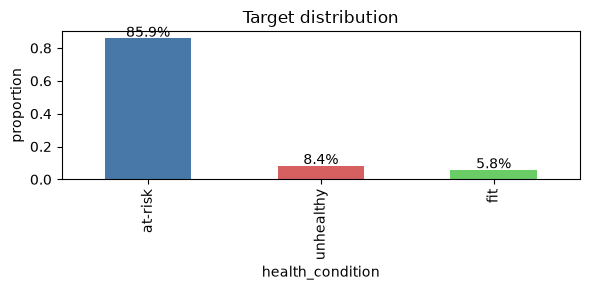

In [3]:
dist = train[TARGET].value_counts(normalize=True)
print(dist.round(4))

fig, ax = plt.subplots(figsize=(6, 3))
dist.plot.bar(ax=ax, color=['#4878A8', '#D65F5F', '#6ACC65'])
ax.set_ylabel('proportion')
ax.set_title('Target distribution')
for i, v in enumerate(dist):
    ax.text(i, v + 0.01, f'{v:.1%}', ha='center')
plt.tight_layout()

So under balanced accuracy the majority-class floor is **⅓**, not 85.9% — and the leaderboard top is ~0.953. The competition is squarely about the minority classes: the winner is whoever best identifies `unhealthy` and `fit` *without* wrecking `at-risk` recall in the process.

## 3. Numeric features by class

**What we're looking for:** *separability*, not pretty plots. For each numeric feature we overlay the class-conditional distributions. A feature helps exactly to the extent that the three curves differ — in location, spread, or shape. Features whose curves coincide are (marginally) useless, though they could still matter in interaction with others.

We use density-normalized histograms rather than raw counts — with an 86/8/6 split, raw counts would make the minority classes invisible.

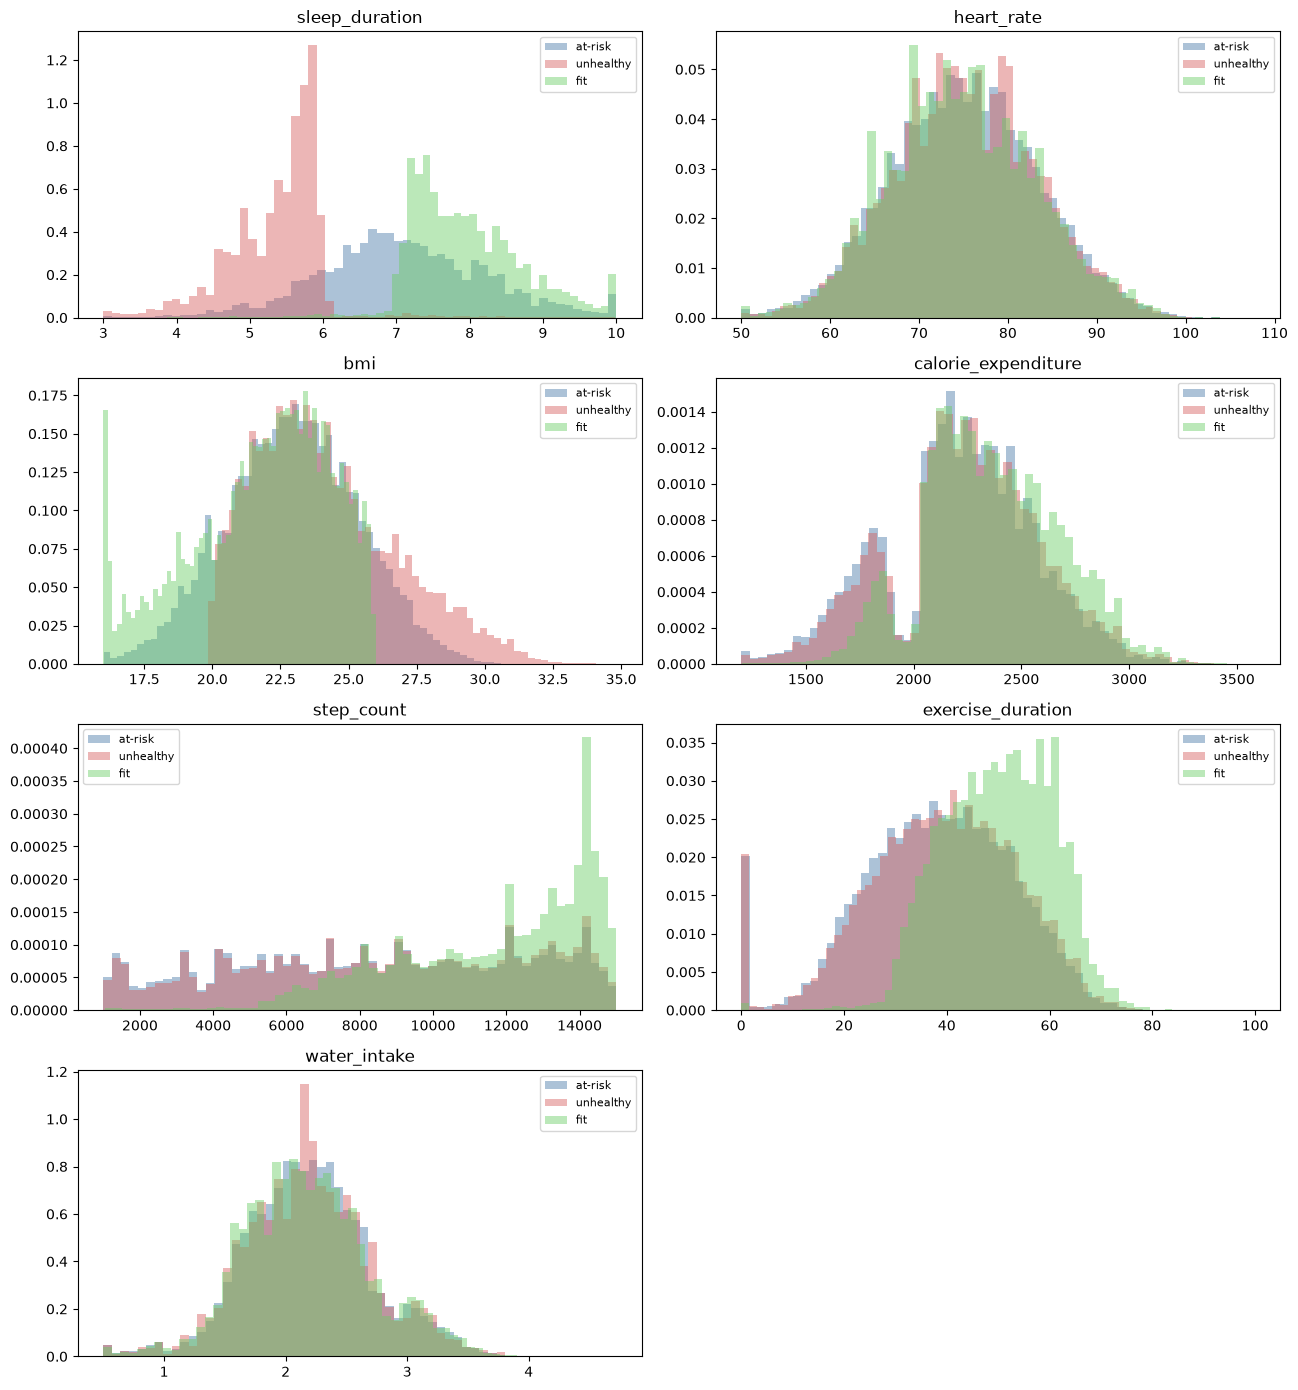

In [4]:
fig, axes = plt.subplots(4, 2, figsize=(13, 14))
colors = {'at-risk': '#4878A8', 'unhealthy': '#D65F5F', 'fit': '#6ACC65'}
for ax, col in zip(axes.flat, NUM):
    for cls, color in colors.items():
        vals = train.loc[train[TARGET] == cls, col].dropna()
        ax.hist(vals, bins=60, density=True, alpha=0.45, label=cls, color=color)
    ax.set_title(col)
    ax.legend(fontsize=8)
axes.flat[-1].axis('off')
plt.tight_layout()

In [5]:
train.groupby(TARGET)[NUM].mean().round(2).T

health_condition,at-risk,fit,unhealthy
sleep_duration,7.09,7.95,5.37
heart_rate,75.10,74.80,75.26
bmi,22.95,21.83,24.12
calorie_expenditure,2214.94,2363.99,2245.42
step_count,8406.71,11651.31,8670.23
exercise_duration,37.96,50.04,39.04
water_intake,2.19,2.18,2.19


**Reading the plots:**

- **`sleep_duration` separates hard**: `unhealthy` averages ~5.4h, `at-risk` ~7.1h, `fit` ~8.0h. Clean monotone story.
- **`step_count` and `exercise_duration` isolate `fit`**: ~11,650 steps and ~50 min for `fit` vs ~8,500 / ~38 for the other two — but they barely separate `at-risk` from `unhealthy`.
- **`bmi` is monotone the other way**: `fit` ~21.8 < `at-risk` ~23.0 < `unhealthy` ~24.1. Modest but real.
- **`heart_rate` and `water_intake` are marginally dead**: class means within noise of each other. Candidates for signal only via interactions or missingness (see §5).
- **`calorie_expenditure`** mildly favors `fit`.

**Lesson:** one look at class-conditional means already predicts which features a GBM will rank as important. If notebook 02's feature importances disagree strongly with this table, that's a red flag worth investigating, not a curiosity.

## 4. Categorical features by class

**What we're looking for:** conditional distributions. `pd.crosstab(..., normalize='index')` answers: *given this category level, what's the target distribution?* Compare each row to the overall (85.9 / 8.4 / 5.8) baseline — deviation from it is signal.

In [6]:
for c in CAT:
    ct = pd.crosstab(train[c], train[TARGET], normalize='index')
    ct = ct[['at-risk', 'unhealthy', 'fit']]
    print(f"--- {c} ---")
    print(ct.round(3), "\n")

--- diet_type ---
health_condition  at-risk  unhealthy    fit
diet_type                                  
balanced            0.851      0.087  0.061
non-veg             0.868      0.081  0.052
veg                 0.857      0.083  0.060 



--- stress_level ---
health_condition  at-risk  unhealthy    fit
stress_level                               
high                0.718      0.279  0.004
low                 0.797      0.003  0.201
medium              0.994      0.003  0.003 



--- sleep_quality ---
health_condition  at-risk  unhealthy    fit
sleep_quality                              
average             0.859      0.083  0.057
good                0.888      0.030  0.082
poor                0.830      0.136  0.035 



--- physical_activity_level ---
health_condition         at-risk  unhealthy    fit
physical_activity_level                           
active                     0.743      0.085  0.172
moderate                   0.911      0.085  0.003
sedentary                  0.917      0.080  0.002 



--- smoking_alcohol ---
health_condition  at-risk  unhealthy    fit
smoking_alcohol                            
no                  0.867      0.055  0.079
occasional          0.859      0.084  0.058
yes                 0.851      0.112  0.037 



--- gender ---
health_condition  at-risk  unhealthy    fit
gender                                     
female              0.857      0.086  0.057
male                0.857      0.080  0.063
other               0.862      0.085  0.053 



**This is the single most important table of the notebook.**

- **`stress_level` is a monster.** `medium` → 99.4% `at-risk` (the model can nearly hard-code that rule). `high` → 27.9% `unhealthy` but 0.4% `fit`. `low` → 20.1% `fit` but 0.3% `unhealthy`. In other words: stress level almost *determines which minority class is even possible*.
- **`physical_activity_level` gates `fit`**: `active` → 17.2% `fit`; `moderate`/`sedentary` → ~0.2–0.3% `fit`. Being fit essentially requires being active in this data.
- **`sleep_quality` and `smoking_alcohol`** shift the minority balance moderately (poor sleep → more `unhealthy`; smoking → 11.2% `unhealthy`, 3.7% `fit`).
- **`diet_type` and `gender` are marginally dead** — rows barely deviate from baseline.

**Lesson:** the minority classes look *conditionally* predictable: `unhealthy` ≈ high stress + short sleep; `fit` ≈ low stress + active + high steps. Interactions between these categoricals and the strong numerics (§3) are the obvious feature-engineering territory for notebook 03. Also note these three categoricals have a natural order (low<medium<high, poor<average<good, sedentary<moderate<active) — notebook 03 will test ordinal encoding.

## 5. Missingness analysis

Every column has missing values (1–12%). Before deciding *what to do about them*, ask the diagnostic question: **is missingness itself informative?**

Textbook framing — MCAR (missing completely at random: safe to impute), MAR (missingness depends on observed values), MNAR (missingness depends on the *missing value itself* — e.g., people with unhealthy BMI skip the weigh-in). In practice with tree models the actionable test is simpler: **does the target distribution shift when a column is missing?** If yes, missingness is a feature, and naive imputation would *destroy* signal.

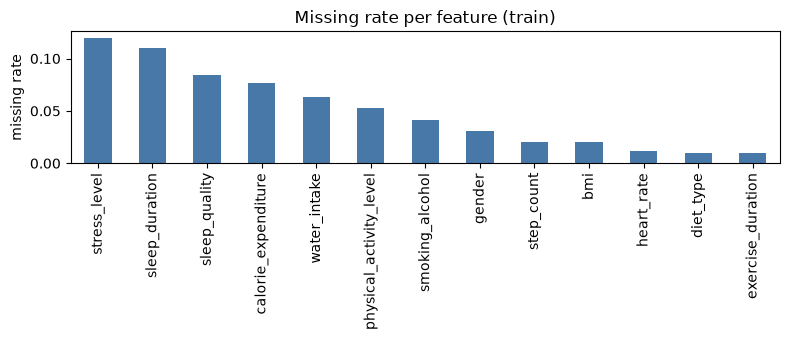

In [7]:
miss_rates = train[FEATURES].isna().mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 3.5))
miss_rates.plot.bar(ax=ax, color='#4878A8')
ax.set_ylabel('missing rate')
ax.set_title('Missing rate per feature (train)')
plt.tight_layout()

In [8]:
overall = train[TARGET].value_counts(normalize=True)
rows = []
for c in FEATURES:
    m = train[c].isna()
    d = train.loc[m, TARGET].value_counts(normalize=True)
    rows.append({'feature': c, 'n_missing': int(m.sum()),
                 **{f'{cls}_when_missing': d.get(cls, 0) for cls in overall.index}})
miss_target = pd.DataFrame(rows).set_index('feature').round(4)
print(f"overall: {dict(overall.round(4))}")
miss_target.sort_values('n_missing', ascending=False)

overall: {'at-risk': np.float64(0.8587), 'unhealthy': np.float64(0.0836), 'fit': np.float64(0.0577)}


,n_missing,at-risk_when_missing,unhealthy_when_missing,fit_when_missing
feature,,,,
stress_level,82811,0.8589,0.0836,0.0575
sleep_duration,75999,0.8593,0.0834,0.0573
sleep_quality,58331,0.8596,0.0822,0.0582
calorie_expenditure,52853,0.8580,0.0840,0.0580
water_intake,43477,0.8551,0.0869,0.0581
physical_activity_level,36621,0.8594,0.0834,0.0572
smoking_alcohol,28582,0.8568,0.0855,0.0577
gender,21373,0.8583,0.0860,0.0557
step_count,13916,0.8621,0.0809,0.0570


**Reading the table:** most columns' missingness is boring — the conditional target distribution matches the overall one. Two exceptions:

- **`bmi` missing is strongly informative**: `unhealthy` collapses from 8.4% → **2.9%** and `fit` rises to 8.2%. A `bmi_missing` flag is essentially a free feature.
- **`heart_rate` missing** is mildly informative (`unhealthy` 8.4% → 7.4%).

**Modeling consequence (to be tested, not assumed):** LightGBM handles NaN natively by learning which side of each split missing values go — so it can partially exploit this *without our help*. Notebook 03 will test whether explicit missing-indicator flags add anything on top, and whether imputation helps or hurts. Hypothesis from this table: imputing `bmi` without keeping a flag should hurt.

## 6. Train vs test drift check

**Why we check:** our entire experimental method (notebook 02 onward) rests on "CV score on train predicts performance on test." That only holds if train and test come from the same distribution. We compare summary stats and missing rates.

In [9]:
drift = pd.DataFrame({
    'train_mean': train[NUM].mean(), 'test_mean': test[NUM].mean(),
    'train_std': train[NUM].std(), 'test_std': test[NUM].std(),
}).round(3)
print(drift)
print()
miss_cmp = pd.DataFrame({'train_missing': train[FEATURES].isna().mean(),
                         'test_missing': test[FEATURES].isna().mean()}).round(4)
print(miss_cmp)

                     train_mean  test_mean  train_std  test_std
sleep_duration            6.993      6.994      1.215     1.216
heart_rate               75.097     75.080      8.175     8.115
bmi                      22.985     22.985      2.482     2.479
calorie_expenditure    2226.085   2225.515    347.532   347.817
step_count             8615.953   8626.631   3929.400  3924.647
exercise_duration        38.751     38.797     14.742    14.711
water_intake              2.189      2.192      0.518     0.519



                         train_missing  test_missing
sleep_duration                  0.1101        0.1101
heart_rate                      0.0114        0.0114
bmi                             0.0201        0.0201
calorie_expenditure             0.0766        0.0766
step_count                      0.0202        0.0202
exercise_duration               0.0100        0.0100
water_intake                    0.0630        0.0630
diet_type                       0.0100        0.0100
stress_level                    0.1200        0.1200
sleep_quality                   0.0845        0.0845
physical_activity_level         0.0531        0.0531
smoking_alcohol                 0.0414        0.0414
gender                          0.0310        0.0310


**Result: no drift, to an almost suspicious degree.** Means match to ~3 decimals and missing rates match to 4 decimals. This is the signature of a single synthetic generation split randomly into train/test.

**Consequence:** this is the best possible case for CV trust — we should expect a small, stable CV↔LB gap. If we later see a large gap, the bug is in *our pipeline* (leakage, wrong fold usage), not in the data.

## 7. Duplicates & synthetic-data quirks

Playground data is generated by a model trained on a real dataset. Known quirk categories worth 30 seconds each: duplicated rows (can inflate CV), value-granularity artifacts (synthetic generators often produce oddly-rounded values), and impossible values (they matter for trust in features, less so for trees).

In [10]:
print("exact duplicate rows (features only):", train.duplicated(subset=FEATURES).sum())
print("exact duplicate rows (features + target):", train.duplicated(subset=FEATURES + [TARGET]).sum())
print()
for c in NUM:
    print(f"{c}: {train[c].nunique()} unique values, sample: {sorted(train[c].dropna().unique())[:5]}")

exact duplicate rows (features only): 0


exact duplicate rows (features + target): 0

sleep_duration: 701 unique values, sample: [np.float64(3.0), np.float64(3.01), np.float64(3.02), np.float64(3.03), np.float64(3.04)]
heart_rate: 537 unique values, sample: [np.float64(50.0), np.float64(50.1), np.float64(50.2), np.float64(50.3), np.float64(50.4)]


bmi: 1596 unique values, sample: [np.float64(16.0), np.float64(16.01), np.float64(16.02), np.float64(16.03), np.float64(16.04)]
calorie_expenditure: 2101 unique values, sample: [np.float64(1200.0), np.float64(1201.0), np.float64(1202.0), np.float64(1203.0), np.float64(1204.0)]


step_count: 12807 unique values, sample: [np.float64(1002.0), np.float64(1004.0), np.float64(1005.0), np.float64(1006.0), np.float64(1007.0)]
exercise_duration: 856 unique values, sample: [np.float64(0.0), np.float64(0.1), np.float64(0.2), np.float64(0.3), np.float64(0.4)]


water_intake: 400 unique values, sample: [np.float64(0.5), np.float64(0.51), np.float64(0.52), np.float64(0.53), np.float64(0.54)]


No duplicates. Numerics are rounded to 1–2 decimals (generator artifact) but nothing exploitable jumps out. Good — no data-cleaning rabbit holes needed.

## 8. EDA conclusions — what notebooks 02–04 will act on

1. **Metric is balanced accuracy** (established in §9): per-class recall is the currency; minority classes are ⅔ of the score. Class weights and per-class decision tuning are first-class citizens, not afterthoughts.
2. **Strong features, ranked by eyeball:** `stress_level` ≫ `sleep_duration`, `step_count`, `physical_activity_level`, `exercise_duration` > `bmi`, `sleep_quality`, `smoking_alcohol`, `calorie_expenditure` > `heart_rate`, `water_intake`, `diet_type`, `gender` (≈ dead marginally). *Check:* notebook 02's feature importances should broadly agree.
3. **Minority classes are conditionally gated:** `fit` needs `active` + low stress + high steps; `unhealthy` concentrates in high stress + short sleep. → notebook 03 tests interactions like `stress_level × sleep_duration`, `activity × step_count`. Under balanced accuracy these gates are where the score lives.
4. **`bmi_missing` is a real feature** (unhealthy 8.4%→2.9% when missing). → notebook 03 tests missing-indicator flags; hypothesis: naive imputation *without* flags will hurt.
5. **Three categoricals are ordinal** (`stress_level`, `sleep_quality`, `physical_activity_level`). → notebook 03 tests ordinal vs native-categorical encoding.
6. **Zero train/test drift** → expect a tight CV↔LB gap; a big gap later means *our* bug.
7. **No duplicates, no cleaning needed.**

## 9. Naive baseline submission — a one-submission metric probe

Predict `at-risk` for every row. **Why bother submitting something this dumb:** it (a) verifies the submission pipeline end-to-end before any model is at stake, and (b) *tests our belief about the metric*. Under plain accuracy this must score ≈ 0.859 (the majority frequency). Under balanced accuracy it must score exactly ⅓. The two hypotheses make sharply different predictions — one cheap submission distinguishes them.

In [11]:
sub = pd.DataFrame({'id': test['id'], TARGET: 'at-risk'})
assert len(sub) == len(test)
sub.to_csv('../submissions/01-majority.csv', index=False)
print(sub.head())
print(f"rows: {len(sub)}")

       id health_condition
0  690088          at-risk
1  690089          at-risk
2  690090          at-risk
3  690091          at-risk
4  690092          at-risk
rows: 295753


### Result

**Public LB score: `0.33333`** — exactly ⅓.

Our original expectation (≈ 0.859, assuming plain accuracy) was **falsified**. All-majority scoring exactly ⅓ is the fingerprint of **balanced accuracy**: recall is 1.0 on `at-risk` and 0 on the other two classes, and (1+0+0)/3 = ⅓. (Cross-checked against top public kernels, which use `sklearn.metrics.balanced_accuracy_score`.) Plain accuracy would have given 0.859; macro-F1 ≈ 0.31, not exactly ⅓.

**Lesson:** a baseline submission isn't just a floor — it's an experiment. Design it so different beliefs about the competition predict different outcomes, and one submission tells you which world you're in.

**Strategy update:** minority-class recall is now ⅔ of the score. Class weighting, resampling, and per-class decision-threshold optimization move from "nice-to-have" (notebook 04's original framing) to the *core* of the modeling problem.

Next: notebook 02 builds the CV harness — scoring **balanced accuracy** — the trust anchor for every experiment after it.